# B2 · Genetic algorithm planner and E4 (live session)

PLAN §7 B2 and §9 E4; drift item 9. Stream B owns it.

The GA searches over whole weekly plans. A plan is a **chromosome** with one **gene** per member who has an allowed
option; the gene says which option (0 = no contact). The GA keeps a **population** of plans, picks parents by
**tournament**, mixes them by **uniform crossover**, changes a few genes by **mutation**, **repairs** any plan that breaks a
limit, and carries the best plans over unchanged (**elitism**). The population is **seeded** with the greedy plan.

The planner's objective adds two interactions to the plain sum (decision #5): **spillover** (a contacted member's value
rises by β × own uplift × weighted share of classmates also contacted, β = 0.5) and **diminishing returns** per instructor
(the n-th most valuable contact among one instructor's members counts 1 / (1 + d·(n−1)), d = 0.02). With β = d = 0 it is
the linear objective from `b_plan_model`.

The GA lives in `anchorai.optimisation.ga` (the planner uses the same code); this notebook imports it.

**Honesty notes.** The scenario's truth has no spillover, so E4 (graded by the truth) cannot reward those terms; E5
(`b_exact`) measures the GA as an optimiser against CP-SAT. Class cohorts come from A's attendance table until C's
KG function lands (HANDOFFS #34). The E4 grid runs dozens of GA searches on 6 parallel workers (about 3 GB of RAM): about 8 minutes in total.

## 1. Load

Three instances that differ only in their uplift estimates: **CBR** (the planner's default), **T-learner** and **perfect
knowledge** (`true_uplift` itself, the E4 ceiling PLAN lists as optional). Cohort rows: one per member and class, weight =
share of the member's own class visits.

**Look for:** 2,469 options for 1,227 members; 1,611 members in 18 classes under 9 instructors.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from anchorai.db.session import get_engine
from anchorai.optimisation.baselines import POLICIES
from anchorai.optimisation.ga import (
    BETA,
    DECAY,
    build_problem,
    chosen,
    encode,
    load_cohorts,
    objective,
    repair,
    run_ga,
)
from anchorai.optimisation.model import (
    HORIZON_MONTHS,
    load_instance,
    load_tlearner_uplift,
    plan_value,
    violations,
)
from anchorai.scenario.tables import read_tables
from joblib import Parallel, delayed
from sqlmodel import Session

FIG, RES = Path("figures"), Path("results")
# About 0.5 GB per worker: more than this can exhaust a 16 GB machine alongside the app and IDE.
N_JOBS = 6
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

tables = read_tables()
truth = tables["true_uplift"].set_index(["member_id", "offer_id"])["uplift"]
session = Session(get_engine())
ESTIMATES = {
    "CBR": None,
    "T-learner": load_tlearner_uplift(),
    "perfect knowledge": truth,
}
instances = {name: load_instance(session, uplift=u) for name, u in ESTIMATES.items()}
options = {
    name: inst.options.reset_index(drop=True) for name, inst in instances.items()
}
instance = instances["CBR"]

cohorts = (
    load_cohorts()
)  # class cohort rows (HANDOFFS #7); from attendance until C's KG function (#34)
print(
    f"{len(options['CBR'])} options for {options['CBR']['member_id'].nunique()} members | "
    f"{cohorts['member_id'].nunique()} members in {cohorts['class_id'].nunique()} classes, {cohorts['instructor_id'].nunique()} instructors"
)
cohorts.head()

2469 options for 1227 members | 1611 members in 18 classes, 9 instructors


,member_id,class_id,weight,instructor_id
0,M0001,K06,1.000000,I03
1,M0002,K13,0.546306,I07
2,M0002,K17,0.362643,I09
3,M0002,K18,0.091051,I09
4,M0004,K09,1.000000,I05


## 2. The problem as arrays

One gene per member with at least one option; gene `k` picks that member's k-th option. Class weights are divided by
(class size − 1) so spillover is a share of classmates.

**Look for:** 1,227 genes; 498 of them attend a class (only they feel spillover and diminishing returns); most members
have 1–3 options.

In [2]:
limits = instance.limits()
problem = build_problem(options["CBR"], cohorts, limits)
sizes = np.array([len(o) for o in problem.slot_options])
print(
    f"{len(sizes)} genes, {problem.share.shape[1]} classes, {(problem.group >= 0).sum()} genes in a class"
)
print(
    "options per gene (excluding 'no contact'):",
    pd.Series(sizes).value_counts().sort_index().to_dict(),
)

1227 genes, 18 classes, 498 genes in a class
options per gene (excluding 'no contact'): {1: 412, 2: 447, 3: 309, 4: 59}


## 3. The objective

**Look for:** with β = d = 0 the objective equals `plan_value` from `b_plan_model` exactly (the linear check). Under the
full objective the greedy plan is worth a little less: diminishing returns cost more than spillover adds.

In [3]:
print(f"spillover β = {BETA}, diminishing returns d = {DECAY}")
greedy = POLICIES["greedy-uplift"](options["CBR"], limits)
picks = greedy.index.to_numpy()
print(
    f"linear check: objective(β=0, d=0) = {objective(problem, picks, 0, 0):,.2f} vs plan_value = {plan_value(greedy):,.2f}"
)
print(
    f"greedy plan under the full objective (β={BETA}, d={DECAY}): {objective(problem, picks):,.2f}"
)

spillover β = 0.5, diminishing returns d = 0.02
linear check: objective(β=0, d=0) = 3,666.15 vs plan_value = 3,666.15
greedy plan under the full objective (β=0.5, d=0.02): 3,648.42


## 4. Repair

Ranks the picked options by value per share of budget and staff time and drops the weakest until every limit holds
(budget, staff minutes, trainer minutes, stock). Contact caps and rules are already enforced by the options table.

**Look for:** a random plan breaks every limit; after repair it breaks none. A feasible plan is left unchanged.

In [4]:
rng = np.random.default_rng(0)
random_genes = np.array([rng.integers(0, n + 1) for n in sizes])
fixed = repair(problem, random_genes, limits)
seed_genes = encode(problem, picks)
print(
    f"random plan: {(random_genes > 0).sum()} contacts, violations {violations(options['CBR'].iloc[chosen(problem, random_genes)], options['CBR'], limits)}"
)
print(
    f"repaired:    {(fixed > 0).sum()} contacts, violations {violations(options['CBR'].iloc[chosen(problem, fixed)], options['CBR'], limits)}"
)
print(
    "repair leaves the feasible greedy plan unchanged:",
    bool((repair(problem, seed_genes, limits) == seed_genes).all()),
)

random plan: 820 contacts, violations {'budget ($)': 11277.0, 'staff minutes': 17370.0, 'trainer minutes': 13020.0, 'free_pt_session stock': 197.0}
repaired:    281 contacts, violations {}
repair leaves the feasible greedy plan unchanged: True


## 5. The GA

Population 100, up to 300 generations, tournament of 3, uniform crossover (70%), about 2 gene changes per child, 2
elites, stop after 60 generations without improvement. A penalty (dollars per unit over a limit) replaces repair when
`use_repair=False`, for the E5 ablation.

**Look for:** three seeds climbing together from the greedy seed (dashed line) and levelling off; no violations.
This is the **planner's own** (estimated) objective, not the truth.

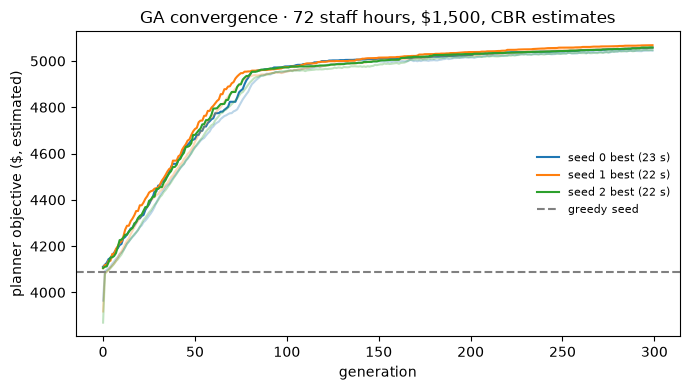

greedy 4,088 -> GA 5,058; violations {}


In [5]:
week = instance.limits(1500, 72 * 60)
problem_72 = build_problem(options["CBR"], cohorts, week)
seed_72 = encode(problem_72, POLICIES["greedy-uplift"](options["CBR"], week).index)
runs = Parallel(n_jobs=N_JOBS)(
    delayed(run_ga)(problem_72, week, seed_72, seed=s) for s in range(3)
)
fig, ax = plt.subplots(figsize=(7, 4))
for s, (genes, log, secs) in enumerate(runs):
    ax.plot(log["generation"], log["best"], label=f"seed {s} best ({secs:.0f} s)")
    ax.plot(log["generation"], log["mean"], alpha=0.3, color=ax.lines[-1].get_color())
ax.axhline(
    objective(problem_72, chosen(problem_72, seed_72)),
    color="grey",
    ls="--",
    label="greedy seed",
)
ax.set_xlabel("generation")
ax.set_ylabel("planner objective ($, estimated)")
ax.set_title("GA convergence · 72 staff hours, $1,500, CBR estimates")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "b2_ga_convergence.png")
plt.show()
plan = options["CBR"].iloc[chosen(problem_72, runs[0][0])]
print(
    f"greedy {objective(problem_72, chosen(problem_72, seed_72)):,.0f} -> GA {objective(problem_72, chosen(problem_72, runs[0][0])):,.0f}; "
    f"violations {violations(plan, options['CBR'], week)}"
)

## 6. E4 (a): how good is each optimiser?

Every planner gets the **true** uplift as its estimates, so differences come only from how well each one searches.
Graded by the truth: extra members retained and true net value (true uplift × fee × 6 − cost). GA over 3 seeds; the
baselines are deterministic except contact-all (seed 0).

**Look for:** `violations` all 0 (the assert). GA ≥ greedy-uplift at every setting, and both far above contact-all
and risk-top-k. Ties where one limit dominates and greedy's ordering is already optimal.

In [6]:
def true_value(plan: pd.DataFrame) -> dict:
    """Grade a plan with the hidden truth: extra members kept and their value net of cost (no spillover in the truth)."""
    u = truth.reindex(
        pd.MultiIndex.from_frame(plan[["member_id", "offer_id"]])
    ).to_numpy()
    return {
        "extra_retained": u.sum(),
        "true_value": (u * plan["monthly_value"].to_numpy() * HORIZON_MONTHS).sum()
        - plan["cost"].sum(),
        "spend": plan["cost"].sum(),
        "staff_minutes": plan["staff_minutes"].sum(),
        "contacts": len(plan),
    }


def one_setting(est, hours, budget, seeds):
    """Every planner at one setting, all fed the same estimates and limits; GA repeated over seeds."""
    opts, week = options[est], instances[est].limits(budget, hours * 60)
    prob = build_problem(opts, cohorts, week)
    rows = []
    for name, policy in POLICIES.items():
        plan = policy(opts, week, 0)
        rows.append(
            {
                "planner": name,
                "seed": 0,
                "violations": len(violations(plan, opts, week)),
                **true_value(plan),
            }
        )
    seed_genes = encode(prob, POLICIES["greedy-uplift"](opts, week).index)
    for s in seeds:
        genes, log, secs = run_ga(prob, week, seed_genes, seed=s)
        plan = opts.iloc[chosen(prob, genes)]
        rows.append(
            {
                "planner": "GA",
                "seed": s,
                "violations": len(violations(plan, opts, week)),
                "seconds": secs,
                "generations": len(log),
                **true_value(plan),
            }
        )
    return pd.DataFrame(rows).assign(estimates=est, staff_hours=hours, budget=budget)


SEEDS = range(3)
grid = [(h, b) for h in (36, 72, 120) for b in (500, 1000, 1500, 2000, 4000)]
e4_optimiser = pd.concat(
    Parallel(n_jobs=N_JOBS)(
        delayed(one_setting)("perfect knowledge", h, b, SEEDS) for h, b in grid
    )
)
assert e4_optimiser["violations"].eq(0).all(), "a planner returned an infeasible plan"
e4_optimiser.round(3).to_csv(RES / "e4_optimiser.csv", index=False)
optimiser_table = (
    e4_optimiser.groupby(["staff_hours", "budget", "planner"])["extra_retained"]
    .mean()
    .unstack("planner")
)
optimiser_table.round(1)

planner               GA  contact-all  greedy-uplift  risk-top-k
staff_hours budget                                              
36          500     33.8         11.5           30.1        13.7
            1000    34.6         11.4           30.1        14.3
            1500    34.9         11.2           31.5        14.4
            2000    35.0         11.2           33.5        14.4
            4000    35.1         11.2           33.9        14.4
72          500     43.1         16.1           43.1        16.4
            1000    47.9         19.3           45.9        20.4
            1500    51.8         22.3           47.7        23.4
            2000    55.3         23.1           49.2        24.0
            4000    58.4         23.1           54.7        24.0
120         500     43.1         16.1           43.1        16.4
            1000    50.1         19.3           50.1        20.4
            1500    56.3         22.3           56.3        23.4
            2000    62.3         23.1           62.2        24.0
            4000    79.5         23.1           74.1        24.0

## 7. E4 (b): what the estimates do to it

The same planners fed CBR or T-learner estimates, graded by the truth.

**Look for:** on perfect knowledge the GA beats greedy; on T-learner estimates they are level; on CBR estimates the GA
does **worse**. That is the optimiser's curse: the harder a planner optimises noisy estimates, the more it picks options
whose estimates happen to be too high.

In [7]:
settings = [
    (est, h, b)
    for est in ("CBR", "T-learner")
    for h in (36, 72, 120)
    for b in (1500, 4000)
]
e4_estimates = pd.concat(
    Parallel(n_jobs=N_JOBS)(
        delayed(one_setting)(est, h, b, SEEDS) for est, h, b in settings
    )
)
assert e4_estimates["violations"].eq(0).all(), "a planner returned an infeasible plan"
e4_all = pd.concat(
    [e4_estimates, e4_optimiser[e4_optimiser["budget"].isin([1500, 4000])]]
)
e4_all.round(3).to_csv(RES / "e4_estimates.csv", index=False)
gap = (
    e4_all[e4_all["planner"].isin(["greedy-uplift", "GA"])]
    .groupby(["estimates", "staff_hours", "budget", "planner"])["true_value"]
    .mean()
    .unstack("planner")
)
gap["GA vs greedy"] = (gap["GA"] / gap["greedy-uplift"] - 1).map("{:+.1%}".format)
display(gap.round(0))
e4_all.groupby(["estimates", "staff_hours", "budget", "planner"])[
    "extra_retained"
].mean().unstack("planner").round(1)

planner                                    GA  greedy-uplift GA vs greedy
estimates         staff_hours budget                                     
CBR               36          1500     6691.0         6861.0        -2.5%
                              4000     6224.0         6181.0        +0.7%
                  72          1500    15783.0        16948.0        -6.9%
                              4000    11813.0        12564.0        -6.0%
                  120         1500    18734.0        19275.0        -2.8%
                              4000    20478.0        22445.0        -8.8%
T-learner         36          1500    11270.0        11459.0        -1.6%
                              4000    11337.0        11319.0        +0.2%
                  72          1500    16730.0        16736.0        -0.0%
                              4000    16468.0        16693.0        -1.3%
                  120         1500    16900.0        16859.0        +0.2%
                              4000    21006.0        21277.0        -1.3%
perfect knowledge 36          1500    14003.0        13015.0        +7.6%
                              4000    14125.0        13766.0        +2.6%
                  72          1500    20327.0        19045.0        +6.7%
                              4000    22301.0        21354.0        +4.4%
                  120         1500    21968.0        21979.0        -0.1%
                              4000    29732.0        28127.0        +5.7%

planner                                 GA  contact-all  greedy-uplift  \
estimates         staff_hours budget                                     
CBR               36          1500    19.0         11.2           19.4   
                              4000    18.4         11.2           18.3   
                  72          1500    40.8         22.3           42.5   
                              4000    35.0         23.1           36.1   
                  120         1500    48.8         22.3           50.1   
                              4000    57.8         23.1           60.7   
T-learner         36          1500    27.9         11.2           27.9   
                              4000    28.1         11.2           28.0   
                  72          1500    43.6         22.3           43.6   
                              4000    44.1         23.1           43.9   
                  120         1500    44.1         22.3           44.0   
                              4000    59.4         23.1           60.0   
perfect knowledge 36          1500    34.9         11.2           31.5   
                              4000    35.1         11.2           33.9   
                  72          1500    51.8         22.3           47.7   
                              4000    58.4         23.1           54.7   
                  120         1500    56.3         22.3           56.3   
                              4000    79.5         23.1           74.1   

planner                               risk-top-k  
estimates         staff_hours budget              
CBR               36          1500          14.4  
                              4000          14.4  
                  72          1500          23.4  
                              4000          24.0  
                  120         1500          23.4  
                              4000          24.0  
T-learner         36          1500          14.4  
                              4000          14.4  
                  72          1500          23.4  
                              4000          24.0  
                  120         1500          23.4  
                              4000          24.0  
perfect knowledge 36          1500          14.4  
                              4000          14.4  
                  72          1500          23.4  
                              4000          24.0  
                  120         1500          23.4  
                              4000          24.0

## 8. Figures

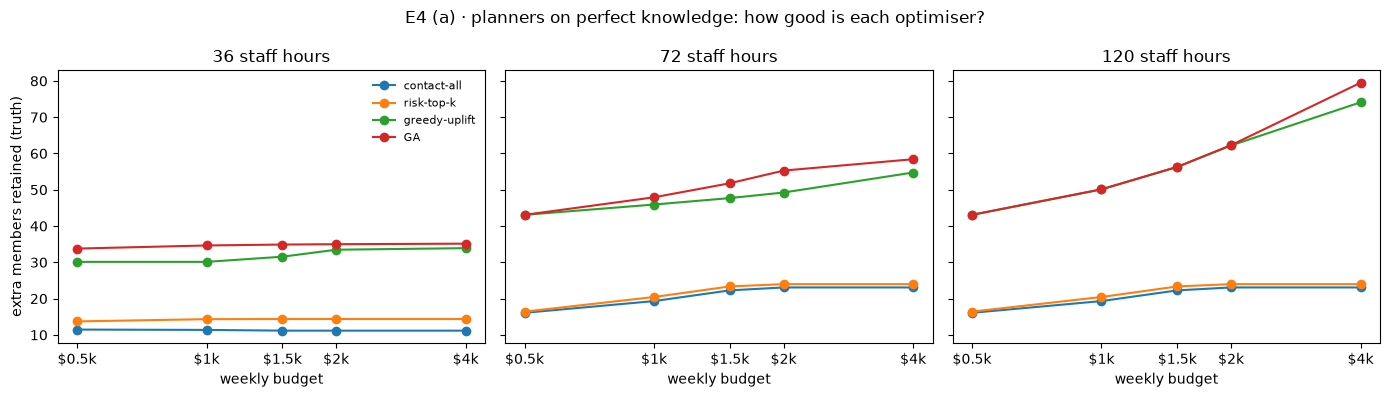

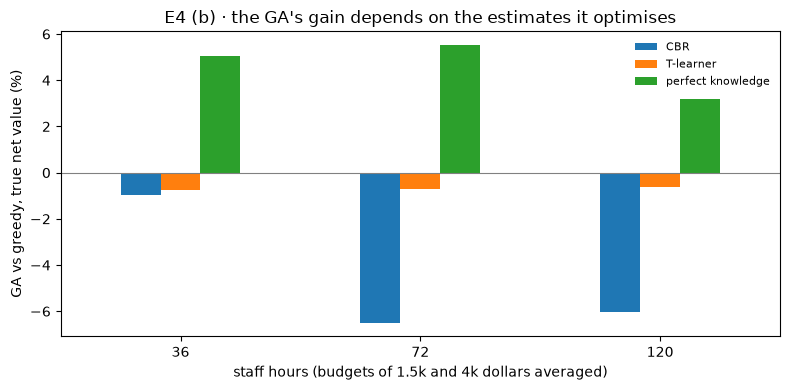

In [8]:
planners = ["contact-all", "risk-top-k", "greedy-uplift", "GA"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, hours in zip(axes, (36, 72, 120)):
    level = optimiser_table.xs(hours, level="staff_hours")
    for name in planners:
        ax.plot(level.index, level[name], marker="o", label=name)
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks(level.index, [f"${b / 1000:g}k" for b in level.index])
    ax.set_title(f"{hours} staff hours")
    ax.set_xlabel("weekly budget")
axes[0].set_ylabel("extra members retained (truth)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("E4 (a) · planners on perfect knowledge: how good is each optimiser?")
fig.tight_layout()
fig.savefig(FIG / "e4_optimiser.png")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
lift = (
    e4_all[e4_all["planner"].isin(["greedy-uplift", "GA"])]
    .groupby(["estimates", "staff_hours", "planner"])["true_value"]
    .mean()
    .unstack("planner")
)
(100 * (lift["GA"] / lift["greedy-uplift"] - 1)).unstack("estimates").plot.bar(
    ax=ax, rot=0
)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("staff hours (budgets of 1.5k and 4k dollars averaged)")
ax.set_ylabel("GA vs greedy, true net value (%)")
ax.set_title("E4 (b) · the GA's gain depends on the estimates it optimises")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "e4_estimates.png")
plt.show()

## Findings (2026-10-19)

1. **Always feasible.** Every GA and baseline plan in E4 broke no limit.
2. **The GA is the better optimiser.** On perfect knowledge it keeps more members than greedy-uplift wherever two limits
   interact (36 h and $1.5k: 34.9 vs 31.5; 72 h and $4k: 58.4 vs 54.7; 120 h and $4k: 79.5 vs 74.1) and ties where one
   limit dominates. Both keep 2–3× more than contact-all and risk-top-k.
3. **Its gain depends on the estimates.** True net value, GA vs greedy: up to +8% on perfect knowledge (level where one limit
   dominates), within ±2% on T-learner estimates, −3% to −9% on CBR estimates at 72 and 120 h (the optimiser's curse). Added to HANDOFFS #33.
4. **Convergence.** About +24% on the planner's own objective over the greedy seed within ~80 generations, still
   creeping up at 300; about 24 s per run at 72 h.
5. **Spillover and diminishing returns are planning assumptions** the truth cannot grade; E5 tests the GA against CP-SAT
   on the objective itself.